# Imports & File Upload

Saving colouredblobs.png to colouredblobs.png


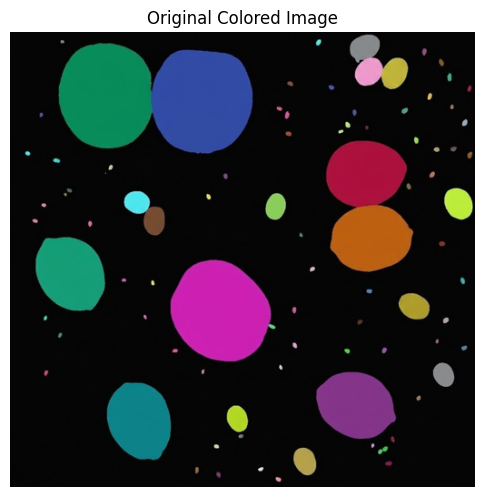

Image size: 512 x 501


In [18]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import os
from IPython.display import display, FileLink

uploaded = files.upload()
filename = next(iter(uploaded))

original = Image.open(filename).convert('RGB')

original.thumbnail((512, 512))
width, height = original.size

plt.figure(figsize=(6, 6))
plt.imshow(original)
plt.title('Original Colored Image')
plt.axis('off')
plt.show()

print("Image size:", width, "x", height)

# Grayscale & Global Thresholding

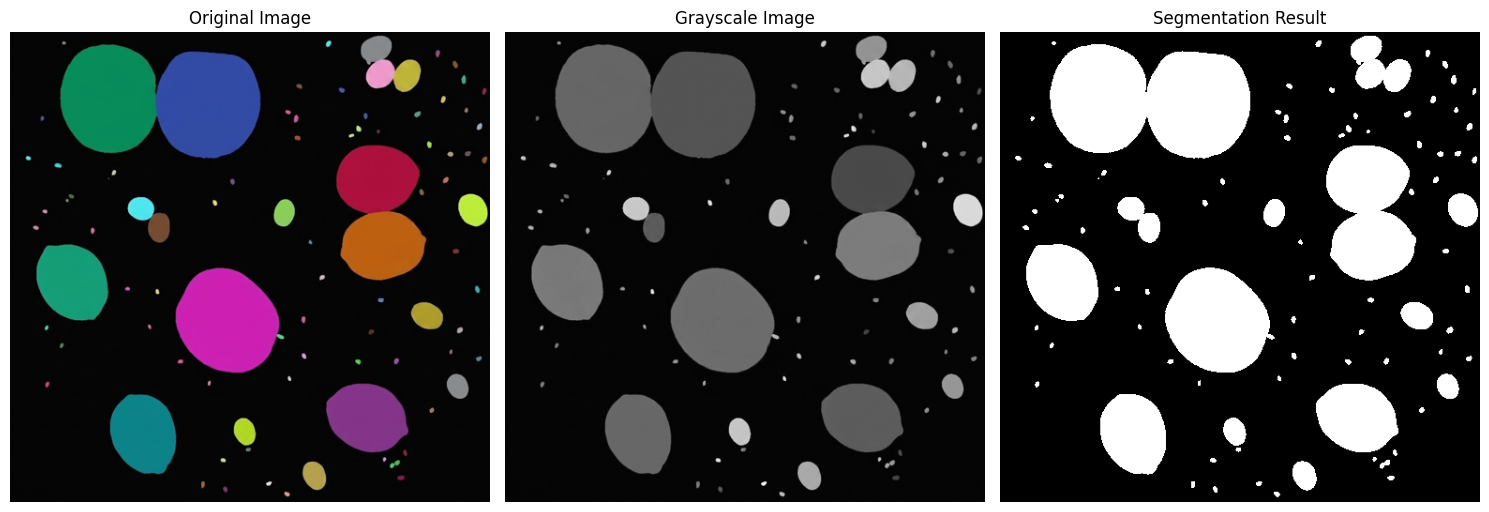

In [19]:
gray_image = original.convert('L')

width, height = gray_image.size

gray = [
    [gray_image.getpixel((x, y)) for x in range(width)]
    for y in range(height)
]

THRESHOLD = 30
INVERT = False

def threshold_segment(image, threshold=30, invert=False):

    height = len(image)
    width = len(image[0])

    result = [[0 for _ in range(width)] for _ in range(height)]

    for y in range(height):
        for x in range(width):

            is_foreground = image[y][x] >= threshold

            if invert:
                is_foreground = not is_foreground

            result[y][x] = 1 if is_foreground else 0

    return result

segmented = threshold_segment(gray, THRESHOLD, INVERT)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(segmented, cmap='gray', vmin=0, vmax=1)
plt.title('Segmentation Result')
plt.axis('off')

plt.tight_layout()
plt.show()

# Morphological Processing

In [ ]:
kernel = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
]

## Dilation

In [ ]:
def dilation(image, kernel):

    height = len(image)
    width = len(image[0])

    kh = len(kernel)
    kw = len(kernel[0])

    cy = kh // 2
    cx = kw // 2

    result = [[0 for _ in range(width)] for _ in range(height)]

    for y in range(height):
        for x in range(width):

            found = False

            for ky in range(kh):
                for kx in range(kw):

                    if kernel[ky][kx] == 1:

                        ny = y + ky - cy
                        nx = x + kx - cx

                        if 0 <= ny < height and 0 <= nx < width:
                            if image[ny][nx] == 1:
                                found = True
                                break

                if found:
                    break

            result[y][x] = 1 if found else 0

    return result

## Erosion

In [ ]:
def erosion(image, kernel):

    height = len(image)
    width = len(image[0])

    kh = len(kernel)
    kw = len(kernel[0])

    cy = kh // 2
    cx = kw // 2

    result = [[0 for _ in range(width)] for _ in range(height)]

    for y in range(height):
        for x in range(width):

            valid = True

            for ky in range(kh):
                for kx in range(kw):

                    if kernel[ky][kx] == 1:

                        ny = y + ky - cy
                        nx = x + kx - cx

                        if not (0 <= ny < height and 0 <= nx < width):
                            valid = False
                            break

                        if image[ny][nx] == 0:
                            valid = False
                            break

                if not valid:
                    break

            result[y][x] = 1 if valid else 0

    return result

## Opening

In [ ]:
def opening(image, kernel):

    eroded = erosion(image, kernel)
    opened = dilation(eroded, kernel)

    return opened

## Closing

In [ ]:
def closing(image, kernel):

    dilated = dilation(image, kernel)
    closed = erosion(dilated, kernel)

    return closed

## Applying all morphological operations

In [21]:
dilated = dilation(segmented, kernel)

eroded = erosion(segmented, kernel)

opened = opening(segmented, kernel)

closed = closing(segmented, kernel)

opening_closing = closing(opened, kernel)

Morphological processing completed!


# Comparison

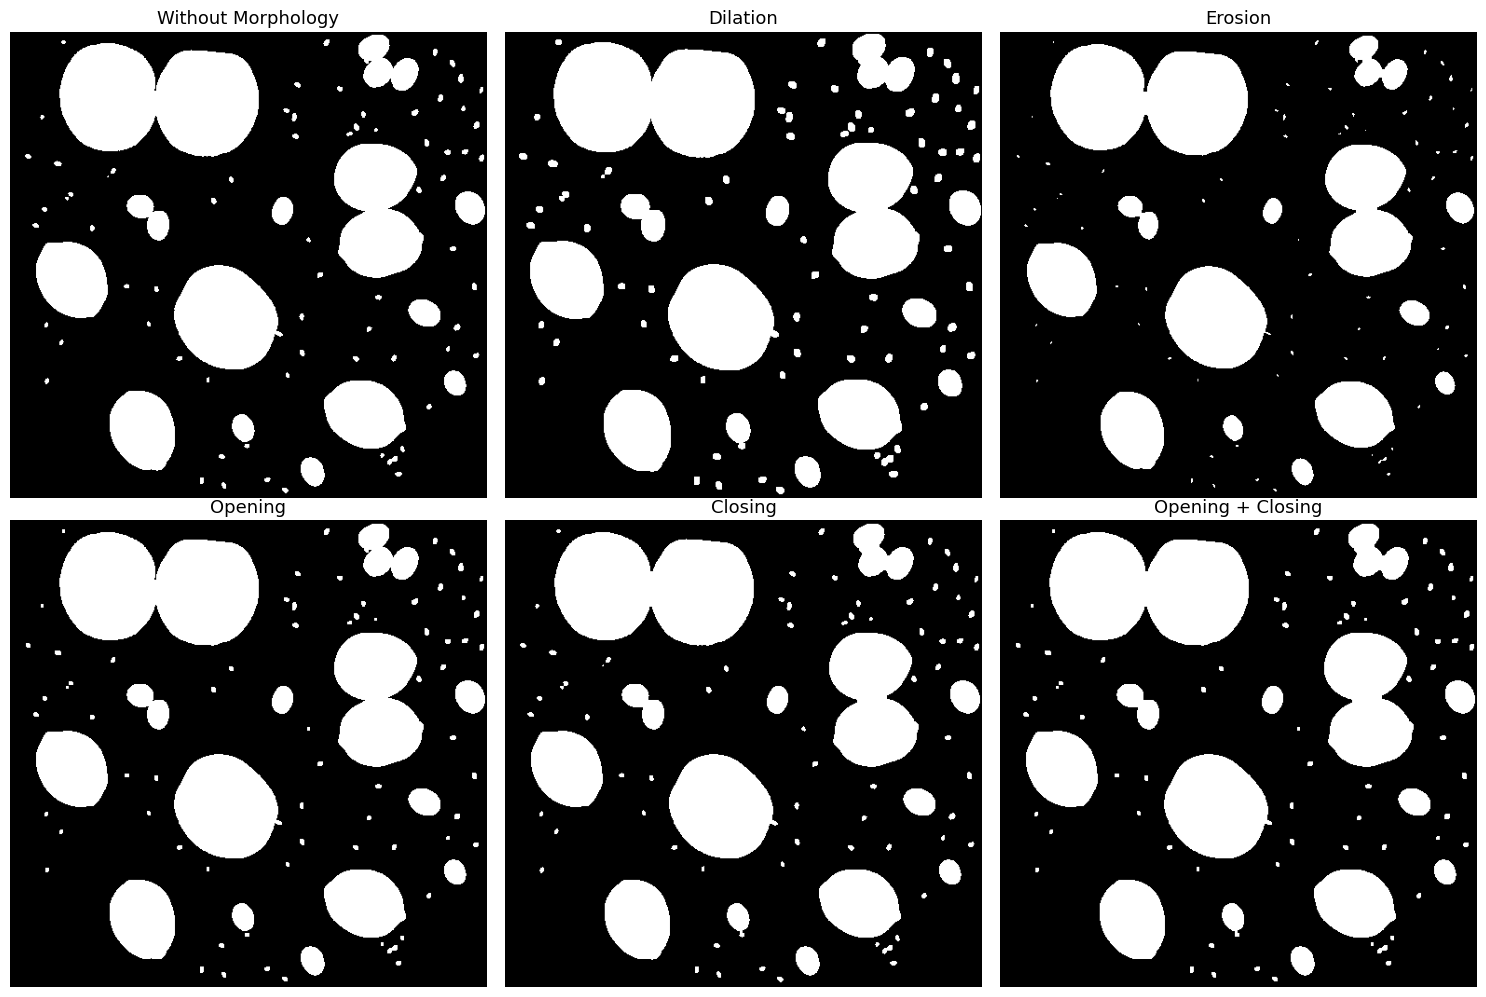

In [22]:
results = [
    (segmented, 'Without Morphology'),
    (dilated, 'Dilation'),
    (eroded, 'Erosion'),
    (opened, 'Opening'),
    (closed, 'Closing'),
    (opening_closing, 'Opening + Closing')
]

plt.figure(figsize=(15, 10))

for i, (img, title) in enumerate(results):

    plt.subplot(2, 3, i + 1)

    plt.imshow(img, cmap='gray', vmin=0, vmax=1)

    plt.title(title, fontsize=13)

    plt.axis('off')


plt.tight_layout()
plt.show()

# Pixel Comparison

In [23]:
def count_foreground(image):
    return sum(sum(row) for row in image)

def count_added(reference, processed):
    height = len(reference)
    width = len(reference[0])

    count = 0

    for y in range(height):
        for x in range(width):
            if reference[y][x] == 0 and processed[y][x] == 1:
                count += 1

    return count

def count_removed(reference, processed):
    height = len(reference)
    width = len(reference[0])

    count = 0

    for y in range(height):
        for x in range(width):
            if reference[y][x] == 1 and processed[y][x] == 0:
                count += 1

    return count

total_pixels = len(segmented) * len(segmented[0])

print("NUMERICAL PIXEL COMPARISON")
print("=" * 100)

print(
    f'{"Method":<22}'
    f'{"Foreground":>15}'
    f'{"Added":>12}'
    f'{"Removed":>12}'
    f'{"Changed":>12}'
    f'{"Difference (%)":>17}'
)

print("-" * 100)

for img, title in results:

    foreground = count_foreground(img)

    added = count_added(segmented, img)
    removed = count_removed(segmented, img)

    changed = added + removed

    percentage = (changed / total_pixels) * 100

    print(
        f'{title:<22}'
        f'{foreground:>15,}'
        f'{added:>12,}'
        f'{removed:>12,}'
        f'{changed:>12,}'
        f'{percentage:>16.2f}%'
    )

NUMERICAL PIXEL COMPARISON
Method                     Foreground       Added     Removed     Changed   Difference (%)
----------------------------------------------------------------------------------------------------
Without Morphology             63,985           0           0           0            0.00%
Dilation                       70,100       6,115           0       6,115            2.38%
Erosion                        58,554           0       5,431       5,431            2.12%
Opening                        63,790           0         195         195            0.08%
Closing                        64,050          65           0          65            0.03%
Opening + Closing              63,851          61         195         256            0.10%


# Saving outputs

In [25]:
output_dir = "/content/morphology_results"
os.makedirs(output_dir, exist_ok=True)

def binary_to_image(image):

    height = len(image)
    width = len(image[0])

    output = Image.new('L', (width, height))

    pixels = [
        255 if image[y][x] == 1 else 0
        for y in range(height)
        for x in range(width)
    ]

    output.putdata(pixels)

    return output

images_to_save = {
    "original.png": original,
    "grayscale.png": gray_image,
    "segmented.png": binary_to_image(segmented),
    "dilation.png": binary_to_image(dilated),
    "erosion.png": binary_to_image(eroded),
    "opening.png": binary_to_image(opened),
    "closing.png": binary_to_image(closed),
    "opening_closing.png": binary_to_image(opening_closing)
}

print("IMAGES SAVED SUCCESSFULLY")
print("=" * 40)

for filename, image in images_to_save.items():

    file_path = os.path.join(output_dir, filename)

    image.save(file_path)

    print(f"\n{filename}")
    display(FileLink(file_path))

IMAGES SAVED SUCCESSFULLY

original.png


/content/morphology_results/original.png


grayscale.png


/content/morphology_results/grayscale.png


segmented.png


/content/morphology_results/segmented.png

... (6 outputs left out)


closing.png


/content/morphology_results/closing.png


opening_closing.png


/content/morphology_results/opening_closing.png